# 5. Uncertainty

Module importing

In [3]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "..")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Library importing

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from src.features import DISCHARGE_FEATURES
from src.models import make_elastic_net, conformal_intervals, coverage
from src.evaluate import parity_plot
from src.config import FIGURES_DIR
from src.data import load_cache
from src.splits import SPLITS
from src.features import build_feature_table

cells = load_cache()
tables = {name: build_feature_table(cells, ids) for name, ids in SPLITS.items()}
y_train = tables["train"]["cycle_life"]



primary_test: coverage 83% (target 90%), median width 272 cycles
secondary_test: coverage 95% (target 90%), median width 465 cycles


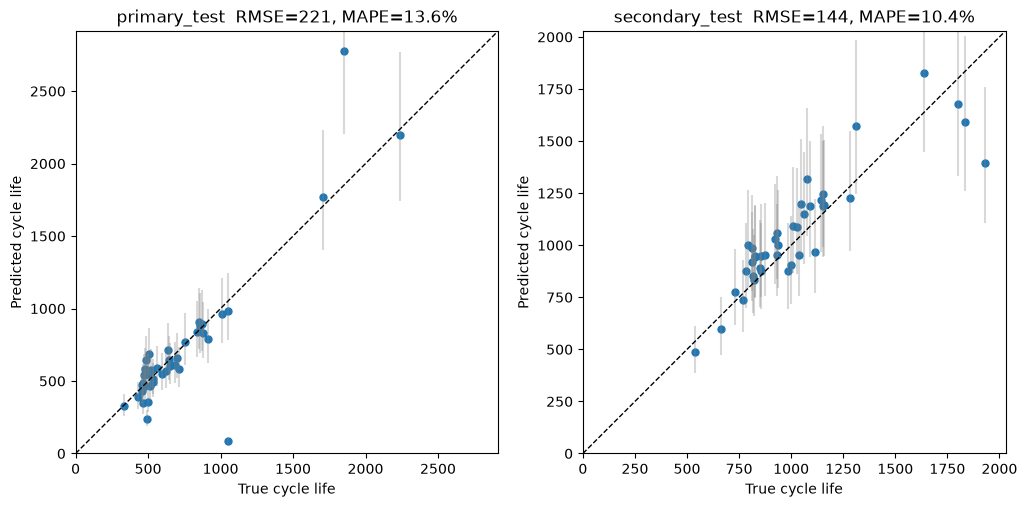

In [5]:
feats = DISCHARGE_FEATURES
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, split in zip(axes, ["primary_test", "secondary_test"]):
    t = tables[split]
    pred, lo, hi = conformal_intervals(make_elastic_net, tables["train"][feats], y_train,
                                       t[feats], alpha=0.1)
    print(f"{split}: coverage {coverage(t['cycle_life'], lo, hi):.0f}% "
          f"(target 90%), median width {np.median(hi - lo):.0f} cycles")
    parity_plot(t["cycle_life"], pred, title=split, ax=ax, lower=lo, upper=hi)
fig.savefig(FIGURES_DIR / "intervals.png", dpi=150, bbox_inches="tight")